# Replicating Regressions

### Data
* Use the file, `data/port_decomp_example.xlsx`.

The data file contains...
* Return rates, $r^i_t$, for various asset classes, (via ETFs.)
* Most notable among these securities is `SPY`, the return on the S&P 500. Denote this as $r^{\text{spy}}_t$.
* A separate tab gives return rates for a particular portfolio, $r^p_t$.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import statsmodels.api as sm


INFILE = 'FINM Portfolio/port_decomp_example.xlsx'

#Info sheet describing each ETF
info = pd.read_excel(INFILE, sheet_name = 'info', index_col = 0)

#Total returns of the ETFs (monthly)
rets = pd.read_excel(INFILE, sheet_name = 'total returns', index_col = 0, parse_dates=True)

#Return of the particular portfolio, r^p
port = pd.read_excel(INFILE, sheet_name = 'portfolio returns', index_col = 0, parse_dates=True)['portfolio']

FREQ = 12

rets.head()

***

# 1. Regression

### 1.
Estimate the regression of the portfolio return on SPY:

$$r^p_t = \alpha + \beta r^{\text{spy}}_t + \epsilon^{p,\text{spy}}_t$$

Specifically, report your estimates of alpha, beta, and the r-squared.

In [ ]:
def regress(y, X, ann = 12):
    '''
    Regression with intercept: y = alpha + beta' X + error
    Dependent Variable Y is the portfolio return
    Independent Variable(s) X are the ETF returns (SPY, or SPY and HYG)
    missing = 'drop' skips months where any series is missing
    '''

    X = sm.add_constant(X) # add a column of 1s to account for the alpha or the intercept
    results = sm.OLS(y, X, missing = 'drop').fit() # fit OLS model

    out = pd.Series({
        'Alpha (monthly)': results.params['const'],
        'Alpha (annualized)': results.params['const'] * ann,
    })
    betas = results.params.drop('const').add_prefix('Beta ') # betas are not annualized, the scaling cancels out
    out = pd.concat([out, betas])
    out['R-squared'] = results.rsquared

    return out


reg_spy = regress(port, rets[['SPY']], ann = FREQ)

display(reg_spy.to_frame('Portfolio on SPY').style.format('{:.4f}'))

- **Alpha:** about −0.17% per month (≈ −1.98% annualized). Small and negative, so after accounting for SPY exposure the portfolio slightly underperforms.
- **Beta:** about 0.63. For every 1% move in SPY, the portfolio moves about 0.63% on average.
- **R-squared:** about 0.76. SPY alone explains roughly 76% of the portfolio's variation; the remaining ~24% comes from other exposures.

### 2.
Estimate the regression of the portfolio return on SPY and on HYG, the return on high-yield corporate bonds, denoted as $r^{\text{hyg}}_t$:

$$r^p_t = \alpha + \beta^{\text{spy}} r^{\text{spy}}_t + \beta^{\text{hyg}} r^{\text{hyg}}_t + \epsilon_t$$

Specifically, report your estimates of alpha, the betas, and the r-squared.

*Note that the parameters (such as $\beta^{\text{spy}}$) in this multivariate model are not the same as used in the univariate model of part 1.

In [ ]:
reg_spy_hyg = regress(port, rets[['SPY', 'HYG']], ann = FREQ)

display(reg_spy_hyg.to_frame('Portfolio on SPY and HYG').style.format('{:.4f}'))

#Side-by-side comparison of the univariate and multivariate models
comparison = pd.DataFrame({'SPY only': reg_spy, 'SPY + HYG': reg_spy_hyg}).reindex(reg_spy_hyg.index)
display(comparison.style.format('{:.4f}', na_rep = '-'))

print(f"Correlation between SPY and HYG: {rets['SPY'].corr(rets['HYG']):.3f}")

- **Alpha:** about −0.15% per month (≈ −1.79% annualized), roughly unchanged from part 1.
- **Betas:** $\beta^{\text{spy}} \approx 0.38$ and $\beta^{\text{hyg}} \approx 0.58$.
- **R-squared:** about 0.82, up from 0.76. Adding HYG explains an extra ~6.6% of the portfolio's variation.

### 3.
Calculate the series of fitted regression values, sometimes referred to as $\hat{y}$ in standard textbooks:

$$\hat{r}^p_t = \hat{\alpha} + \hat{\beta}^{\text{spy}} r^{\text{spy}}_t + \hat{\beta}^{\text{hyg}} r^{\text{hyg}}_t$$

Your statistical package will output these fitted values for you, or you can construct them using the estimated parameters.

What is the correlation of $\hat{r}^p_t$ with $r^p_t$?

How does this compare to the r-squared of the regression in problem 2?

In [4]:
#Construct the fitted values from the estimated parameters in problem 2
alpha_hat = reg_spy_hyg['Alpha (monthly)']
betas_hat = reg_spy_hyg[['Beta SPY', 'Beta HYG']].rename(lambda x: x.replace('Beta ', '')) # relabel to match the columns of rets

port_fitted = alpha_hat + rets[['SPY', 'HYG']] @ betas_hat # r_hat = alpha + beta_spy * r_spy + beta_hyg * r_hyg

corr_fitted = port_fitted.corr(port)

fitted_check = pd.Series({
    'Corr(fitted, actual)': corr_fitted,
    'Corr(fitted, actual) squared': corr_fitted ** 2,
    'R-squared (problem 2)': reg_spy_hyg['R-squared'],
})

display(fitted_check.to_frame('Value').style.format('{:.4f}'))

,Value
"Corr(fitted, actual)",0.9069
"Corr(fitted, actual) squared",0.8225
R-squared (problem 2),0.8225


- The correlation between the fitted values $\hat{r}^p_t$ and the actual portfolio returns $r^p_t$ is about **0.907**.
- Squaring it gives **0.8225**, which is exactly the R-squared from problem 2.

### 4.
How do the SPY betas differ across the univariate and multivariate models? How does this relate to the correlation between $r^{\text{spy}}$ and $r^{\text{hyg}}$?

The SPY beta falls from 0.63 in the univariate model to 0.38 in the multivariate model.

This happens because SPY and HYG are highly correlated (about 0.80). When HYG is left out of the regression, part of the portfolio's high-yield exposure shows up in the SPY beta, since SPY and HYG tend to move together. In the multivariate model, each beta measures the sensitivity to that asset holding the other one constant, so the high-yield part is now attributed to HYG instead.

***

# 2. Decomposing and Replicating

### 1.
The portfolio return, $r^p_t$, is a combination of the base assets that are provided here. Use linear regression to uncover which weights were used in constructing the portfolio.

$$r^p_t = \alpha + (\boldsymbol{\beta})'\boldsymbol{r}_t + \epsilon_t$$

where $\boldsymbol{r}$ denotes the vector of returns for the individual securities.

* What does the regression find were the original weights?
* How precise is the estimation? Consider the R-squared and t-stats.

*Feel free to include an $\alpha$ in this model, even though you know the portfolio is an exact function of the individual securities. The estimation should find $\alpha$ of (nearly) zero.*

In [6]:
#Dependent variable Y is the portfolio, independent variables X are all the ETFs
X_all = sm.add_constant(rets) # add a column of 1s to account for the alpha or the intercept

results_all = sm.OLS(port, X_all, missing = 'drop').fit()

decomp = pd.DataFrame({
    'Weight (beta)': results_all.params,
    't-stat': results_all.tvalues,
}).rename({'const': 'Alpha'})

display(decomp.style.format({'Weight (beta)': '{:.4f}', 't-stat': '{:.2e}'})) # t-stats in scientific notation, some are enormous

print(f"Sum of weights:       {results_all.params.drop('const').sum():.4f}")
print(f"R-squared:            {results_all.rsquared:.4f}")
print(f"Residual volatility:  {results_all.resid.std():.2e}")

,Weight (beta),t-stat
Alpha,0.0000,8.08e+00
SPY,-0.0000,-7.55e-01
EFA,-0.0000,-5.73e-01
EEM,-0.0000,-8.16e-01
PSP,0.2500,2.65e+14
QAI,0.2500,7.13e+13
HYG,0.0000,5.98e-02
DBC,-0.0000,-7.72e-01
IYR,0.2500,3.33e+14
IEF,0.2500,1.03e+14


Sum of weights:       1.0000
R-squared:            1.0000
Residual volatility:  1.87e-16


**Original weights**

The regression finds the portfolio is 25% each in PSP, QAI, IYR and IEF, with zero alpha. 

**Precision**

- R-squared is 1. The four ETFs explain 100% of the portfolio's variation. The residuals are essentially zero (on the order of $10^{-16}$).
- The t-stats are large for the four ETFs in the portfolio and extremely small for the rest. 


### 2.
Suppose that we want to mimic a return, **EEM** using the other returns. Run the following regression–but do so **only using data through the end of `2022`**.

$$r^{EEM}_t = \alpha + (\boldsymbol{\beta}^{\boldsymbol{r}})'\boldsymbol{r}_t + \epsilon_t$$

where $\boldsymbol{r}$ denotes the vector of returns for the other securities, excluding the target, **EEM**.

#### (a)
Report the r-squared and the estimate of the vector, $\boldsymbol{\beta}$.

#### (b)
Report the t-stats of the explanatory returns. Which have absolute value greater than 2?

#### (c)
Plot the returns of **EEM** along with the replication values.

In [7]:
TARGET = 'EEM'

#Dependent variable Y is EEM, independent variables X are all the other ETFs
y_eem = rets[TARGET]
X_other = rets.drop(columns = TARGET)

#In-sample: only data through the end of 2022
y_is = y_eem.loc[:'2022']
X_is = X_other.loc[:'2022']

results_eem = sm.OLS(y_is, sm.add_constant(X_is), missing = 'drop').fit() # add a column of 1s to account for the alpha or the intercept

#(a) R-squared and betas, (b) t-stats
eem_reg = pd.DataFrame({
    'Beta': results_eem.params,
    't-stat': results_eem.tvalues,
}).rename({'const': 'Alpha'})
eem_reg['|t| > 2'] = eem_reg['t-stat'].abs() > 2

display(eem_reg.style.format({'Beta': '{:.4f}', 't-stat': '{:.2f}'}))

print(f"In-sample period:  {y_is.index.min():%Y-%m} to {y_is.index.max():%Y-%m} ({len(y_is)} months)")
print(f"R-squared:         {results_eem.rsquared:.4f}")
print(f"|t-stat| > 2:      {eem_reg.drop('Alpha').query('`|t| > 2`').index.tolist()}")

,Beta,t-stat,|t| > 2
Alpha,0.0014,0.52,False
SPY,-0.2393,-1.56,False
EFA,0.5338,3.67,True
PSP,0.0037,0.03,False
QAI,1.1292,3.01,True
HYG,-0.0069,-0.04,False
DBC,0.0212,0.34,False
IYR,0.0785,0.95,False
IEF,-0.8116,-2.99,True
BWX,0.5937,3.50,True


In-sample period:  2010-01 to 2022-12 (156 months)
R-squared:         0.7676
|t-stat| > 2:      ['EFA', 'QAI', 'IEF', 'BWX']


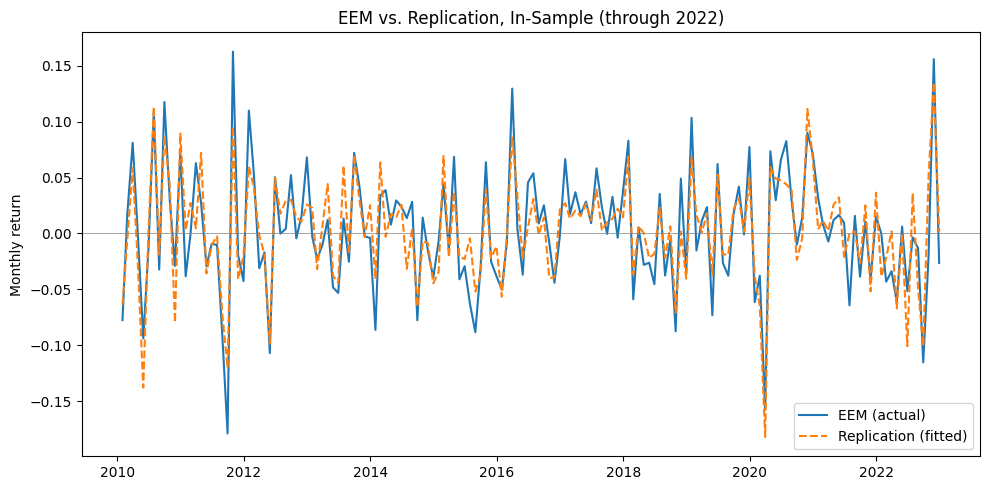

In [9]:
import matplotlib.pyplot as plt

#(c) Replication values = fitted values of the in-sample regression
eem_replication_is = results_eem.fittedvalues

plt.figure(figsize = (10, 5))
plt.plot(y_is, label = 'EEM (actual)', linewidth = 1.5)
plt.plot(eem_replication_is, label = 'Replication (fitted)', linewidth = 1.5, linestyle = '--')
plt.axhline(0, color = 'grey', linewidth = 0.5)
plt.title('EEM vs. Replication, In-Sample (through 2022)')
plt.ylabel('Monthly return')
plt.legend()
plt.tight_layout()
plt.show()

### 3.
Perhaps the replication results in the previous problem are overstated given that they estimated the parameters within a sample and then evaluated how well the result fit in the same sample. This is known as in-sample fit.

Using the estimates through `2022`, (the α and β̂ from the previous problem,) calculate the out-of-sample (OOS) values of the replication, using the `2023-2024` returns, denoted $\boldsymbol{r}^{\text{oos}}_t$:

$$\hat{r}^{EEM}_t = \left(\hat{\boldsymbol{\beta}}^{\boldsymbol{r}}\right)'\boldsymbol{r}^{\text{oos}}_t$$

#### (a)
What is the correlation between $\hat{r}^{EEM}_t$ and $\boldsymbol{r}^{\text{oos}}_t$?

#### (b)
How does this compare to the r-squared from the regression above based on in-sample data, (through `2022`?)

,Value
"OOS correlation (replication, actual EEM)",0.8437
OOS correlation squared,0.7118
In-sample R-squared (through 2022),0.7676


Out-of-sample period: 2023-01 to 2024-12 (24 months)


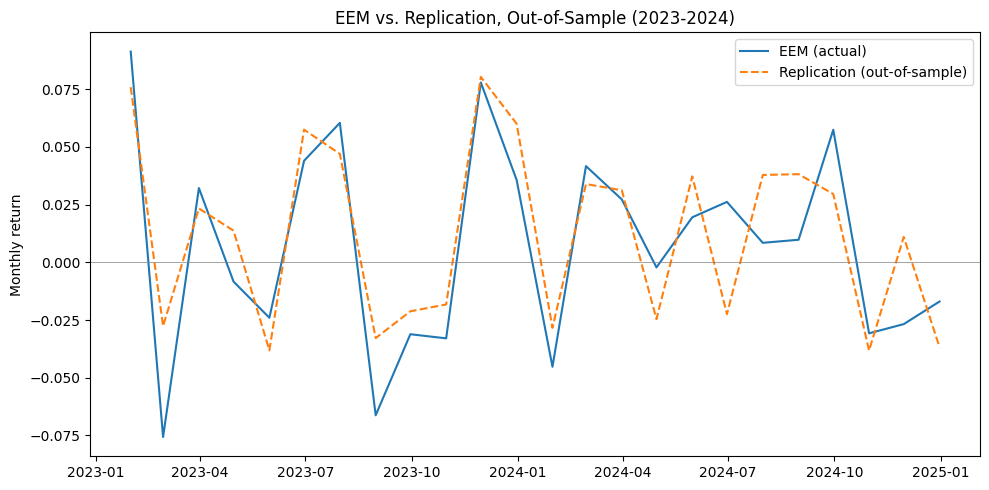

In [10]:
#Out-of-sample: 2023-2024 returns, using the alpha and betas estimated through 2022 (no re-estimating)
y_oos = y_eem.loc['2023':'2024']
X_oos = X_other.loc['2023':'2024']

eem_replication_oos = results_eem.params['const'] + X_oos @ results_eem.params.drop('const') # r_hat = alpha + beta' r_oos

corr_oos = eem_replication_oos.corr(y_oos)

oos_check = pd.Series({
    'OOS correlation (replication, actual EEM)': corr_oos,
    'OOS correlation squared': corr_oos ** 2,
    'In-sample R-squared (through 2022)': results_eem.rsquared,
})

display(oos_check.to_frame('Value').style.format('{:.4f}'))
print(f"Out-of-sample period: {y_oos.index.min():%Y-%m} to {y_oos.index.max():%Y-%m} ({len(y_oos)} months)")

plt.figure(figsize = (10, 5))
plt.plot(y_oos, label = 'EEM (actual)', linewidth = 1.5)
plt.plot(eem_replication_oos, label = 'Replication (out-of-sample)', linewidth = 1.5, linestyle = '--')
plt.axhline(0, color = 'grey', linewidth = 0.5)
plt.title('EEM vs. Replication, Out-of-Sample (2023-2024)')
plt.ylabel('Monthly return')
plt.legend()
plt.tight_layout()
plt.show()

The out-of-sample fit is worse. Out-of-sample, the betas are applied to new data they have never seen. The drop here is fairly modest from 0.77 to around 0.71, so the replication still works reasonably well. The in-sample R-squared overstates how well we can actually mimic EEM.

***

# Private Equity

### Data
* Use the data in `../data/private_equity_data.xlsx`.

The returns are **weekly**, so we annualize the mean with a scaling of 52 and the volatility with a scaling of $\sqrt{52}$. We use **excess** returns (over `SHV`) throughout, so that the Sharpe ratio and alpha are measured relative to the risk-free rate.

In [11]:
PE_FILE = 'FINM Portfolio/private_equity_data.xlsx'

#Info sheet describing each ticker
pe_info = pd.read_excel(PE_FILE, sheet_name = 'descriptions', index_col = 0)

#Excess returns (weekly), SHV has already been subtracted
pe_excess = pd.read_excel(PE_FILE, sheet_name = 'excess returns', index_col = 0, parse_dates=True)

#Annualization factor for weekly data
ANN_W = 52

print(f"Sample: {pe_excess.index.min():%Y-%m-%d} to {pe_excess.index.max():%Y-%m-%d} ({len(pe_excess)} weeks)")
display(pe_info[['shortName']])

Sample: 2015-01-09 to 2025-10-03 (561 weeks)


,shortName
ticker,
SPY,SPDR S&P 500
VTV,Vanguard Value ETF
AGG,iShares Core U.S. Aggregate Bon
HYG,iShares iBoxx $ High Yield Corp
IEF,iShares 7-10 Year Treasury Bond
PSP,Invesco Global Listed Private E
PEX,ProShares Global Listed Private
APO,"Apollo Global Management, Inc."
BX,Blackstone Inc.


# 1. Performance
Calculate performance stats for the assets, both stand-alone (mean, vol, Sharpe) as well as linear decompositions (alpha, beta, info ratio, r-squared).

In [12]:
#Stand-alone performance
pe_summary = pd.DataFrame({
    'Mean': pe_excess.mean() * ANN_W,
    'Vol': pe_excess.std() * np.sqrt(ANN_W),
})
pe_summary['Sharpe'] = pe_summary['Mean'] / pe_summary['Vol']

pe_summary.sort_values('Sharpe', ascending = False).style.format({'Mean': '{:.2%}', 'Vol': '{:.2%}', 'Sharpe': '{:.2f}'})

,Mean,Vol,Sharpe
SPY,12.31%,16.97%,0.73
APO,23.15%,36.79%,0.63
KKR,22.86%,36.50%,0.63
BX,21.76%,35.82%,0.61
VTV,8.65%,16.41%,0.53
CG,14.45%,36.71%,0.39
PSP,4.94%,23.17%,0.21
HYG,-0.47%,9.54%,-0.05
PEX,-1.43%,21.46%,-0.07
IEF,-0.73%,6.44%,-0.11


In [15]:
def regress_on_market(y, x, ann = 52):
    '''
    Regression with intercept: y = alpha + beta * x + error
    Dependent Variable Y is the asset's excess returns
    Independent Variable X is SPY excess returns
    '''

    X = sm.add_constant(x.rename('SPY')) # add a column of 1s to account for the alpha or the intercept
    results = sm.OLS(y, X, missing = 'drop').fit() # fit OLS model
    alpha, beta = results.params['const'], results.params['SPY']

    return pd.Series({
        'Alpha (annualized)': alpha * ann,
        'Market Beta': beta, # not annualized, the scaling cancels out
        'Information Ratio': alpha * ann / (results.resid.std() * np.sqrt(ann)), # alpha divided by the volatility of the residuals (tracking error)
        'R-squared': results.rsquared,
    })

#Linear decomposition of every asset on SPY (SPY on itself is trivial, so drop it)
pe_decomp = pe_excess.drop(columns = 'SPY').apply(lambda y: regress_on_market(y, pe_excess['SPY'], ann = ANN_W)).T

pe_decomp.style.format({'Alpha (annualized)': '{:.2%}', 'Market Beta': '{:.2f}', 'Information Ratio': '{:.2f}', 'R-squared': '{:.2f}'})

,Alpha (annualized),Market Beta,Information Ratio,R-squared
VTV,-2.39%,0.90,-0.39,0.86
AGG,-1.60%,0.07,-0.32,0.05
HYG,-5.70%,0.42,-0.91,0.57
IEF,-0.40%,-0.03,-0.06,0.01
PSP,-9.60%,1.18,-0.83,0.75
PEX,-13.46%,0.98,-0.99,0.60
APO,4.93%,1.48,0.18,0.47
BX,3.74%,1.46,0.14,0.48
KKR,3.48%,1.57,0.14,0.54
CG,-3.59%,1.47,-0.13,0.46


# 2. Replication
Can we replicate private equity `APO` using the following?
* public equity `SPY`
* treasury bonds `IEF`
* high-yield corp bonds `HYG`

How does that compare to `APO` against `SPY` alone?

In [16]:
def replicate(y, X, ann = 52):
    '''
    Replication regression: y = alpha + beta' X + error
    Dependent Variable Y is APO excess returns
    Independent Variables X are the ETFs used to replicate it
    '''

    results = sm.OLS(y, sm.add_constant(X), missing = 'drop').fit() # add a column of 1s to account for the alpha or the intercept

    out = pd.concat([
        pd.Series({'Alpha (annualized)': results.params['const'] * ann}),
        results.params.drop('const').add_prefix('Beta '),
        results.tvalues.rename({'const': 'alpha'}).add_prefix('t-stat '),
    ])
    out['R-squared'] = results.rsquared
    out['Tracking Error (annualized)'] = results.resid.std() * np.sqrt(ann) # volatility of the part we cannot replicate

    return out


apo = pe_excess['APO']

rep_spy = replicate(apo, pe_excess[['SPY']], ann = ANN_W)
rep_3 = replicate(apo, pe_excess[['SPY', 'IEF', 'HYG']], ann = ANN_W)

#Side-by-side comparison, keeping the row order of the bigger model
apo_replication = pd.DataFrame({'SPY only': rep_spy, 'SPY + IEF + HYG': rep_3}).reindex(rep_3.index)

display(apo_replication.style.format('{:.4f}', na_rep = '-'))

print(f"APO volatility (annualized): {apo.std() * np.sqrt(ANN_W):.2%}")
print('Correlation of the replicating assets:')
display(pe_excess[['SPY', 'IEF', 'HYG']].corr().round(2))

,SPY only,SPY + IEF + HYG
Alpha (annualized),0.0493,0.0996
Beta SPY,1.4802,1.0660
Beta IEF,-,-0.7040
Beta HYG,-,0.9310
t-stat alpha,0.5992,1.2335
t-stat SPY,22.0864,10.4291
t-stat IEF,-,-3.9565
t-stat HYG,-,5.1056
R-squared,0.4660,0.4965
Tracking Error (annualized),0.2688,0.2611


APO volatility (annualized): 36.79%
Correlation of the replicating assets:


,SPY,IEF,HYG
SPY,1.00,-0.07,0.75
IEF,-0.07,1.00,0.11
HYG,0.75,0.11,1.00


**Can we replicate APO with SPY, IEF and HYG?** Not well.
- The betas are **SPY 1.07, IEF −0.70, HYG 0.93**, all significant (|t| > 2).
- R-squared is only 0.50, so half of APO's movement can't be explained by these ETFs.

**Compared with SPY alone**
- SPY alone already gets an R-squared of 0.47. Adding IEF and HYG only raises it by 3 percentage points.
- The SPY beta falls from 1.48 to 1.07 because SPY and HYG are correlated (0.75), so some of the "equity" exposure is credit exposure picked up by HYG.

SPY does most of the work, and the bond ETFs add very little. APO has a large part that public market returns can't replicate.